In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler
from sklearn.preprocessing import OneHotEncoder, LabelEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer

In [2]:
df=pd.read_csv('data.csv')

In [3]:
df.head()

,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
0,1,PAYMENT,9839.64,C1231006815,170136.0,160296.36,M1979787155,0.0,0.0,0,0
1,1,PAYMENT,1864.28,C1666544295,21249.0,19384.72,M2044282225,0.0,0.0,0,0
2,1,TRANSFER,181.00,C1305486145,181.0,0.00,C553264065,0.0,0.0,1,0
3,1,CASH_OUT,181.00,C840083671,181.0,0.00,C38997010,21182.0,0.0,1,0
4,1,PAYMENT,11668.14,C2048537720,41554.0,29885.86,M1230701703,0.0,0.0,0,0


In [4]:
df.info(verbose=True)

<class 'pandas.DataFrame'>
RangeIndex: 6362620 entries, 0 to 6362619
Data columns (total 11 columns):
 #   Column          Dtype  
---  ------          -----  
 0   step            int64  
 1   type            str    
 2   amount          float64
 3   nameOrig        str    
 4   oldbalanceOrg   float64
 5   newbalanceOrig  float64
 6   nameDest        str    
 7   oldbalanceDest  float64
 8   newbalanceDest  float64
 9   isFraud         int64  
 10  isFlaggedFraud  int64  
dtypes: float64(5), int64(3), str(3)
memory usage: 706.2 MB


In [5]:
df['isFlaggedFraud'].value_counts()

isFlaggedFraud
0    6362604
1         16
Name: count, dtype: int64

In [6]:
df['isFraud'].value_counts()

isFraud
0    6354407
1       8213
Name: count, dtype: int64

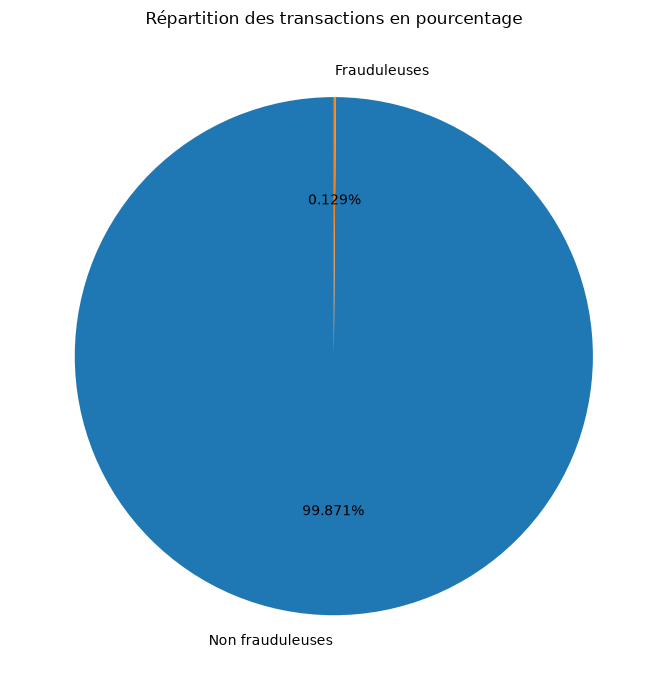

In [7]:
counts = df["isFraud"].value_counts().reindex([0, 1], fill_value=0)
percentages = counts / counts.sum() * 100

plt.figure(figsize=(7, 7))
plt.pie(
    percentages,
    labels=["Non frauduleuses", "Frauduleuses"],
    autopct="%.3f%%",
    startangle=90
)

plt.title("Répartition des transactions en pourcentage")
plt.tight_layout()
plt.show()

In [8]:
df.describe()

,step,amount,oldbalanceOrg,newbalanceOrig,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
count,6.362620e+06,6.362620e+06,6.362620e+06,6.362620e+06,6.362620e+06,6.362620e+06,6.362620e+06,6.362620e+06
mean,2.433972e+02,1.798619e+05,8.338831e+05,8.551137e+05,1.100702e+06,1.224996e+06,1.290820e-03,2.514687e-06
std,1.423320e+02,6.038582e+05,2.888243e+06,2.924049e+06,3.399180e+06,3.674129e+06,3.590480e-02,1.585775e-03
min,1.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
25%,1.560000e+02,1.338957e+04,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
50%,2.390000e+02,7.487194e+04,1.420800e+04,0.000000e+00,1.327057e+05,2.146614e+05,0.000000e+00,0.000000e+00
75%,3.350000e+02,2.087215e+05,1.073152e+05,1.442584e+05,9.430367e+05,1.111909e+06,0.000000e+00,0.000000e+00
max,7.430000e+02,9.244552e+07,5.958504e+07,4.958504e+07,3.560159e+08,3.561793e+08,1.000000e+00,1.000000e+00


In [9]:
df['nameOrig'].nunique()

6353307

In [10]:
df['nameDest'].nunique()

2722362

In [11]:
# Transactions PAYMENT vers un marchand avec un solde destinataire nul
mask = (
    (df["type"] == "PAYMENT")
    & (df["nameDest"].str.startswith("M"))
    & (df["oldbalanceDest"] == 0)
    & (df["newbalanceDest"] == 0)
)

print(df.loc[mask, "isFraud"].value_counts())
print(
    df.loc[mask, "isFraud"]
    .value_counts(normalize=True)
    .mul(100)
    .round(3)
)

isFraud
0    2151495
Name: count, dtype: int64
isFraud
0    100.0
Name: proportion, dtype: float64


In [12]:
print("Dimensions du dataset :", df.shape)


Dimensions du dataset : (6362620, 11)


In [13]:
df.isnull().sum()

step              0
type              0
amount            0
nameOrig          0
oldbalanceOrg     0
newbalanceOrig    0
nameDest          0
oldbalanceDest    0
newbalanceDest    0
isFraud           0
isFlaggedFraud    0
dtype: int64

In [14]:
numeric_cols = [
    "amount",
    "oldbalanceOrg",
    "newbalanceOrig",
    "oldbalanceDest",
    "newbalanceDest"
]

In [15]:
for col in numeric_cols:
    print(f"{col} : {(df[col] < 0).sum()} valeurs négatives")

amount : 0 valeurs négatives
oldbalanceOrg : 0 valeurs négatives


newbalanceOrig : 0 valeurs négatives
oldbalanceDest : 0 valeurs négatives
newbalanceDest : 0 valeurs négatives


In [16]:
print(df["type"].value_counts(dropna=False))

type
CASH_OUT    2237500
PAYMENT     2151495
CASH_IN     1399284
TRANSFER     532909
DEBIT         41432
Name: count, dtype: int64


In [17]:
df["ecartOrig"] = (
    df["oldbalanceOrg"]
    - df["newbalanceOrig"]
    - df["amount"]
)

In [18]:
print("Transactions où le solde émetteur ne correspond pas :",
      (df["ecartOrig"].abs() > 1.01).sum())

Transactions où le solde émetteur ne correspond pas : 5000784


In [19]:
df["ecartDest"] = (
    df["newbalanceDest"]
    - df["oldbalanceDest"]
    - df["amount"]
)

In [20]:
print("Transactions où le solde destinataire ne correspond pas :",
      (df["ecartDest"].abs() > 1.01).sum())

Transactions où le solde destinataire ne correspond pas : 3823834


In [21]:
analyse = df[["type", "isFraud"]].copy()
analyse["ecartorig"] = df["ecartOrig"].abs() > 1.01
analyse["ecartdest"] = df["ecartDest"].abs() > 1.01


In [22]:
resume = analyse.groupby("type").agg(
    nombre_transactions=("isFraud", "size"),
    ecart_emetteur=("ecartorig", "sum"),
    ecart_destinataire=("ecartdest", "sum")
)

In [23]:
resume["pct_ecart_emetteur"] = (
    resume["ecart_emetteur"] / resume["nombre_transactions"] * 100
).round(2)

resume["pct_ecart_destinataire"] = (
    resume["ecart_destinataire"] / resume["nombre_transactions"] * 100
).round(2)

print(resume.sort_values("nombre_transactions", ascending=False))


          nombre_transactions  ecart_emetteur  ecart_destinataire  \
type                                                                
CASH_OUT              2237500         1981123              211658   
PAYMENT               2151495         1101068             2151388   
CASH_IN               1399284         1399281             1399280   
TRANSFER               532909          507529               58063   
DEBIT                   41432           11783                3445   

          pct_ecart_emetteur  pct_ecart_destinataire  
type                                                  
CASH_OUT               88.54                    9.46  
PAYMENT                51.18                  100.00  
CASH_IN               100.00                  100.00  
TRANSFER               95.24                   10.90  
DEBIT                  28.44                    8.31  


In [24]:

balance_cols = [
    "oldbalanceOrg",
    "newbalanceOrig",
    "oldbalanceDest",
    "newbalanceDest"
]

print(
    (df[balance_cols] == 0)
    .sum()
    .rename("Nombre de valeurs égales à zéro")
)

print("\nSoldes nuls par type de transaction :")
print(
    df.groupby("type")[balance_cols]
    .apply(lambda group: (group == 0).sum())
)


oldbalanceOrg     2102449
newbalanceOrig    3609566
oldbalanceDest    2704388
newbalanceDest    2439433
Name: Nombre de valeurs égales à zéro, dtype: int64

Soldes nuls par type de transaction :
          oldbalanceOrg  newbalanceOrig  oldbalanceDest  newbalanceDest
type                                                                   
CASH_IN           13464               0          163573          270871
CASH_OUT        1025799         1985211          324187           11425
DEBIT              6158           11786               0             468
PAYMENT          774245         1101124         2151495         2151495
TRANSFER         282783          511445           65133            5174


In [25]:
mask_orig_zero = df["newbalanceOrig"] == 0

print("Transactions avec nouveau solde émetteur nul :",
      mask_orig_zero.sum())

print("\nRépartition par type :")
print(df.loc[mask_orig_zero, "type"].value_counts())

print("\nStatistiques des montants :")
print(df.loc[mask_orig_zero, "amount"].describe())

print("\nRépartition fraude / non-fraude :")
print(df.loc[mask_orig_zero, "isFraud"].value_counts())

Transactions avec nouveau solde émetteur nul : 3609566

Répartition par type :
type
CASH_OUT    1985211
PAYMENT     1101124
TRANSFER     511445
DEBIT         11786
Name: count, dtype: int64

Statistiques des montants :
count    3.609566e+06
mean     2.408081e+05
std      7.867088e+05
min      0.000000e+00
25%      1.918909e+04
50%      1.049416e+05
75%      2.504347e+05
max      9.244552e+07
Name: amount, dtype: float64

Répartition fraude / non-fraude :
isFraud
0    3601513
1       8053
Name: count, dtype: int64


In [26]:

# Transactions avec montant nul
mask_amount_zero = df["amount"] == 0

print("Nombre de transactions avec montant nul :",
      mask_amount_zero.sum())

print("\nRépartition par type :")
print(df.loc[mask_amount_zero, "type"].value_counts())

print("\nRépartition par fraude :")
print(df.loc[mask_amount_zero, "isFraud"].value_counts())

print("\nExemples :")
display(
    df.loc[
        mask_amount_zero,
        [
            "type",
            "amount",
            "oldbalanceOrg",
            "newbalanceOrig",
            "oldbalanceDest",
            "newbalanceDest",
            "isFraud"
        ]
    ].head(10)
)


Nombre de transactions avec montant nul : 16

Répartition par type :
type
CASH_OUT    16
Name: count, dtype: int64

Répartition par fraude :
isFraud
1    16
Name: count, dtype: int64

Exemples :


,type,amount,oldbalanceOrg,newbalanceOrig,oldbalanceDest,newbalanceDest,isFraud
2736447,CASH_OUT,0.0,0.0,0.0,0.00,0.00,1
3247298,CASH_OUT,0.0,0.0,0.0,0.00,0.00,1
3760289,CASH_OUT,0.0,0.0,0.0,538547.63,538547.63,1
5563714,CASH_OUT,0.0,0.0,0.0,7970766.57,7970766.57,1
5996408,CASH_OUT,0.0,0.0,0.0,76759.90,76759.90,1
5996410,CASH_OUT,0.0,0.0,0.0,2921531.34,2921531.34,1
6168500,CASH_OUT,0.0,0.0,0.0,230289.66,230289.66,1
6205440,CASH_OUT,0.0,0.0,0.0,1328472.86,1328472.86,1
6266414,CASH_OUT,0.0,0.0,0.0,0.00,0.00,1
6281483,CASH_OUT,0.0,0.0,0.0,0.00,0.00,1


In [27]:
fraudes_montant_nul = df.loc[
    (df["amount"] == 0) & (df["isFraud"] == 1)
]

display(fraudes_montant_nul)

print("\nRépartition des soldes :")
display(
    fraudes_montant_nul[
        [
            "oldbalanceOrg",
            "newbalanceOrig",
            "oldbalanceDest",
            "newbalanceDest"
        ]
    ].describe()
)

,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud,ecartOrig,ecartDest
2736447,212,CASH_OUT,0.0,C1510987794,0.0,0.0,C1696624817,0.00,0.00,1,0,0.0,0.0
3247298,250,CASH_OUT,0.0,C521393327,0.0,0.0,C480398193,0.00,0.00,1,0,0.0,0.0
3760289,279,CASH_OUT,0.0,C539112012,0.0,0.0,C1106468520,538547.63,538547.63,1,0,0.0,0.0
5563714,387,CASH_OUT,0.0,C1294472700,0.0,0.0,C1325541393,7970766.57,7970766.57,1,0,0.0,0.0
5996408,425,CASH_OUT,0.0,C832555372,0.0,0.0,C1462759334,76759.90,76759.90,1,0,0.0,0.0
5996410,425,CASH_OUT,0.0,C69493310,0.0,0.0,C719711728,2921531.34,2921531.34,1,0,0.0,0.0
6168500,554,CASH_OUT,0.0,C10965156,0.0,0.0,C1493336195,230289.66,230289.66,1,0,0.0,0.0
6205440,586,CASH_OUT,0.0,C1303719003,0.0,0.0,C900608348,1328472.86,1328472.86,1,0,0.0,0.0
6266414,617,CASH_OUT,0.0,C1971175979,0.0,0.0,C1352345416,0.00,0.00,1,0,0.0,0.0
6281483,646,CASH_OUT,0.0,C2060908932,0.0,0.0,C1587892888,0.00,0.00,1,0,0.0,0.0



Répartition des soldes :


,oldbalanceOrg,newbalanceOrig,oldbalanceDest,newbalanceDest
count,16.0,16.0,1.600000e+01,1.600000e+01
mean,0.0,0.0,9.048885e+05,9.048885e+05
std,0.0,0.0,2.036048e+06,2.036048e+06
min,0.0,0.0,0.000000e+00,0.000000e+00
25%,0.0,0.0,0.000000e+00,0.000000e+00
50%,0.0,0.0,9.226846e+04,9.226846e+04
75%,0.0,0.0,6.560631e+05,6.560631e+05
max,0.0,0.0,7.970767e+06,7.970767e+06


In [28]:
sns.set_theme(style="whitegrid")

# Copie des colonnes nécessaires
df_viz = df[
    ["nameOrig", "nameDest", "isFraud", "type", "amount"]
].copy()

# Utilisation du type entier nullable 'Int64' pour gérer la valeur NaN
df_viz["isFraud"] = df_viz["isFraud"].astype("Int64")

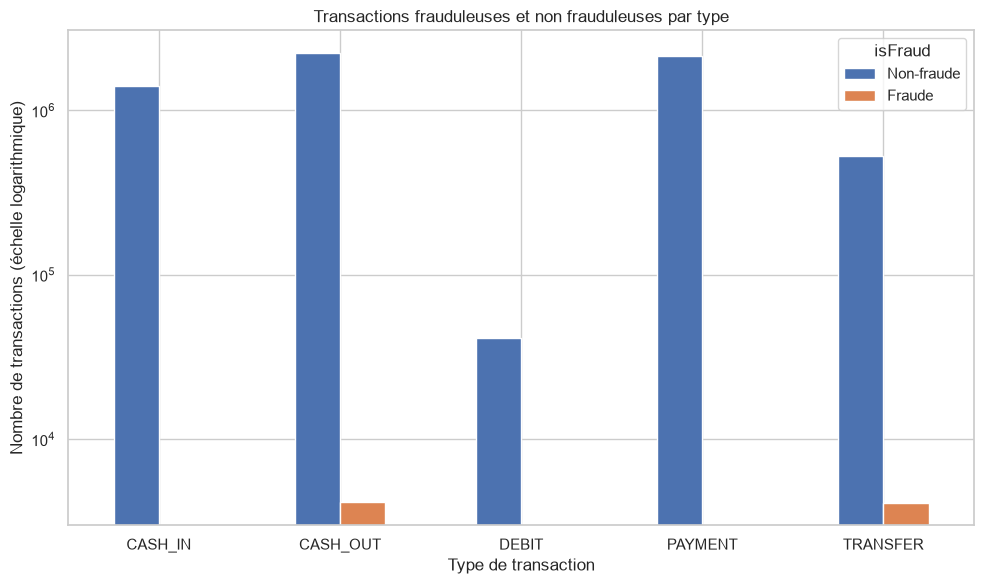

In [29]:

fraud_by_type = (
    df_viz.groupby(["type", "isFraud"])
    .size()
    .unstack(fill_value=0)
    .rename(columns={0: "Non-fraude", 1: "Fraude"})
)

fraud_by_type.plot(
    kind="bar",
    figsize=(10, 6),
    logy=True
)

plt.title("Transactions frauduleuses et non frauduleuses par type")
plt.xlabel("Type de transaction")
plt.ylabel("Nombre de transactions (échelle logarithmique)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


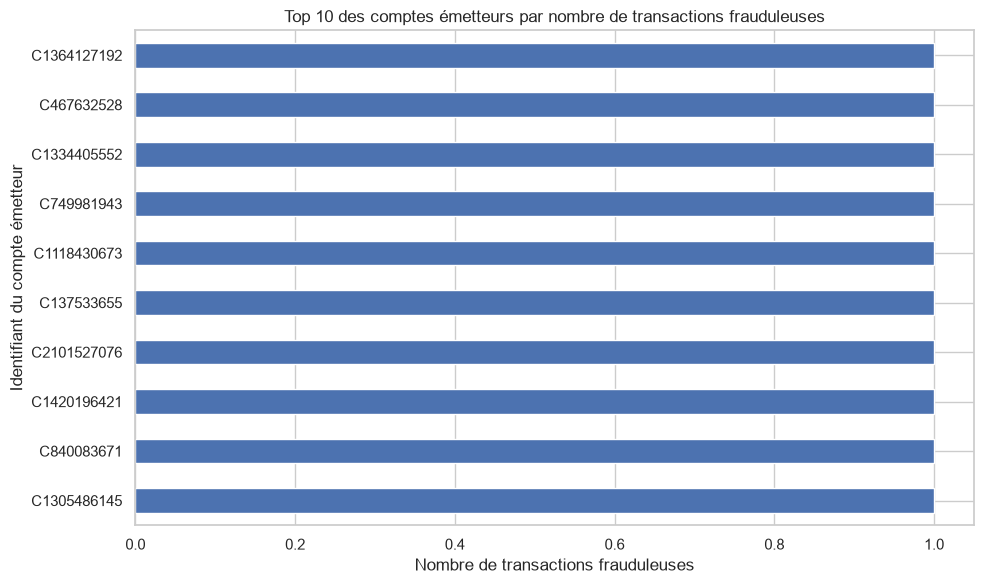

In [30]:

top_orig_fraud = (
    df_viz.loc[df_viz["isFraud"] == 1, "nameOrig"]
    .value_counts()
    .head(10)
    .sort_values()
)

plt.figure(figsize=(10, 6))
top_orig_fraud.plot(kind="barh")

plt.title("Top 10 des comptes émetteurs par nombre de transactions frauduleuses")
plt.xlabel("Nombre de transactions frauduleuses")
plt.ylabel("Identifiant du compte émetteur")
plt.tight_layout()
plt.show()


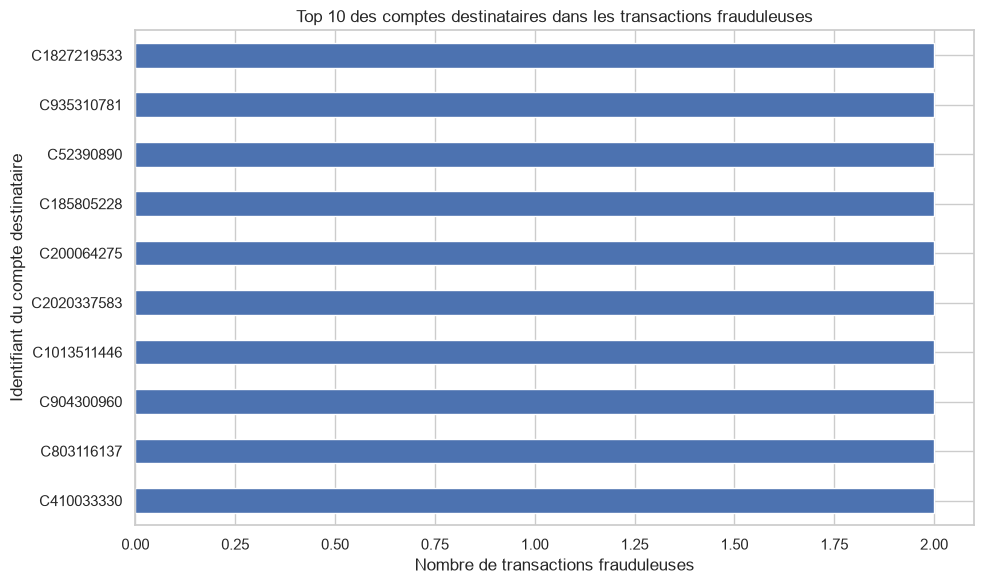

In [31]:

top_dest_fraud = (
    df_viz.loc[df_viz["isFraud"] == 1, "nameDest"]
    .value_counts()
    .head(10)
    .sort_values()
)

plt.figure(figsize=(10, 6))
top_dest_fraud.plot(kind="barh")

plt.title("Top 10 des comptes destinataires dans les transactions frauduleuses")
plt.xlabel("Nombre de transactions frauduleuses")
plt.ylabel("Identifiant du compte destinataire")
plt.tight_layout()
plt.show()


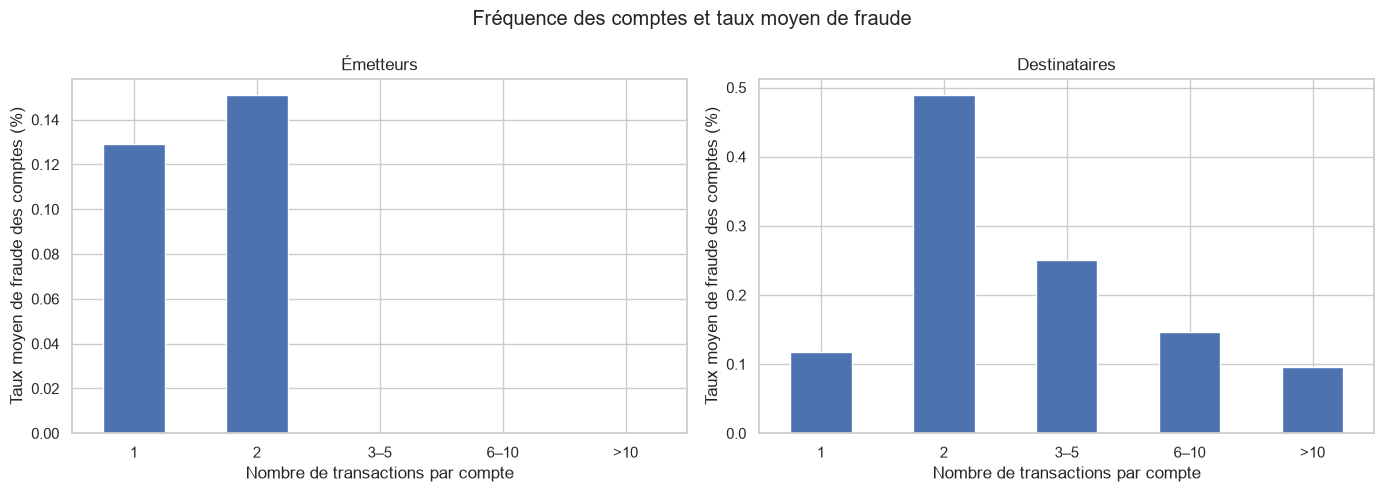

In [32]:

# Analyse séparée des émetteurs et destinataires
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, col, title in [
    (axes[0], "nameOrig", "Émetteurs"),
    (axes[1], "nameDest", "Destinataires")
]:
    account_stats = (
        df_viz.groupby(col)
        .agg(
            nb_transactions=("isFraud", "size"),
            taux_fraude=("isFraud", "mean")
        )
    )

    # Regrouper les comptes par fréquence
    account_stats["groupe"] = pd.cut(
        account_stats["nb_transactions"],
        bins=[0, 1, 2, 5, 10, np.inf],
        labels=["1", "2", "3–5", "6–10", ">10"]
    )

    taux = (
        account_stats.groupby("groupe", observed=False)["taux_fraude"]
        .mean() * 100
    )

    taux.plot(kind="bar", ax=ax)
    ax.set_title(title)
    ax.set_xlabel("Nombre de transactions par compte")
    ax.set_ylabel("Taux moyen de fraude des comptes (%)")
    ax.tick_params(axis="x", rotation=0)

plt.suptitle("Fréquence des comptes et taux moyen de fraude")
plt.tight_layout()
plt.show()


In [33]:
fraud = df[df["isFraud"] == 1]

print("Préfixes des émetteurs frauduleux :")
print(fraud["nameOrig"].str[0].value_counts(dropna=False))

print("\nPréfixes des destinataires frauduleux :")
print(fraud["nameDest"].str[0].value_counts(dropna=False))

Préfixes des émetteurs frauduleux :
nameOrig
C    8213
Name: count, dtype: int64

Préfixes des destinataires frauduleux :
nameDest
C    8213
Name: count, dtype: int64


In [34]:
fraud_by_type = (
    df.groupby("type")["isFraud"]
    .agg(
        nombre_fraudes="sum",
        nombre_transactions="count",
        taux_fraude="mean"
    )
)

fraud_by_type["taux_fraude_pct"] = (
    fraud_by_type["taux_fraude"] * 100
).round(4)

print(
    fraud_by_type[
        ["nombre_fraudes", "nombre_transactions", "taux_fraude_pct"]
    ].sort_values("nombre_fraudes", ascending=False)
)

          nombre_fraudes  nombre_transactions  taux_fraude_pct
type                                                          
CASH_OUT            4116              2237500           0.1840
TRANSFER            4097               532909           0.7688
CASH_IN                0              1399284           0.0000
DEBIT                  0                41432           0.0000
PAYMENT                0              2151495           0.0000


          nombre_fraudes  nombre_transactions  taux_fraude_pct
type                                                          
CASH_OUT            4116              2237500           0.1840
TRANSFER            4097               532909           0.7688
CASH_IN                0              1399284           0.0000
DEBIT                  0                41432           0.0000
PAYMENT                0              2151495           0.0000


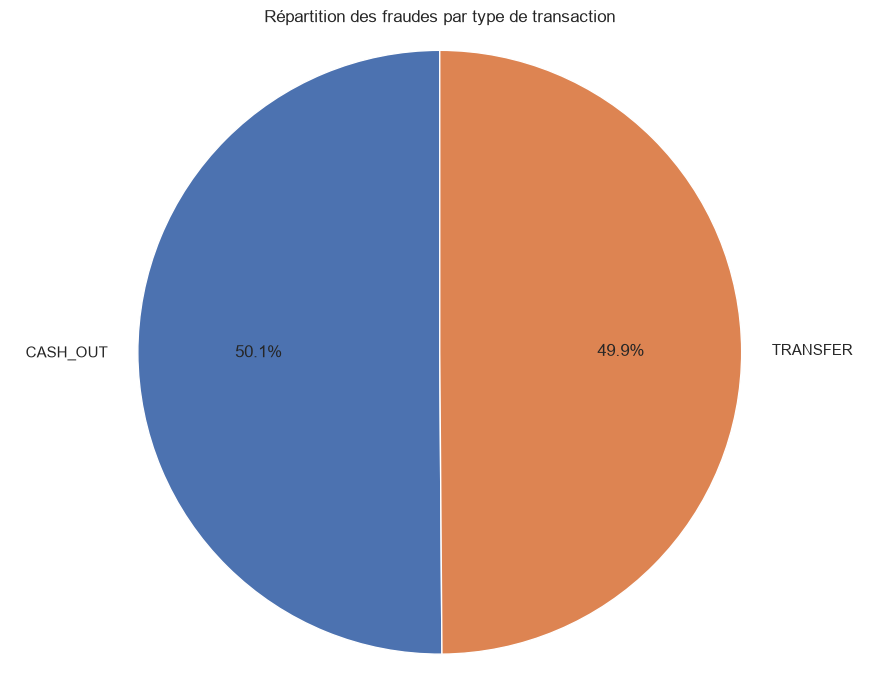

In [35]:

# Calcul des statistiques
fraud_by_type = (
    df.groupby("type")["isFraud"]
    .agg(
        nombre_fraudes="sum",
        nombre_transactions="count",
        taux_fraude="mean"
    )
)

fraud_by_type["taux_fraude_pct"] = (
    fraud_by_type["taux_fraude"] * 100
).round(4)

# Afficher le tableau des résultats
print(
    fraud_by_type[
        ["nombre_fraudes", "nombre_transactions", "taux_fraude_pct"]
    ].sort_values("nombre_fraudes", ascending=False)
)

# Préparer les données du diagramme circulaire
fraudes = fraud_by_type[fraud_by_type["nombre_fraudes"] > 0][
    "nombre_fraudes"
]

# Créer le pie chart
plt.figure(figsize=(9, 7))

plt.pie(
    fraudes,
    labels=fraudes.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Répartition des fraudes par type de transaction")
plt.axis("equal")
plt.tight_layout()
plt.show()

In [36]:


# Séparer les transactions normales et frauduleuses
normales = df.loc[df["isFraud"] == 0, "amount"]
fraudes = df.loc[df["isFraud"] == 1, "amount"]

# Comparer les statistiques
comparaison = df.groupby("isFraud")["amount"].agg(
    nombre="count",
    moyenne="mean",
    mediane="median",
    ecart_type="std",
    minimum="min",
    maximum="max"
)

comparaison.index = ["Normales", "Frauduleuses"]

print(comparaison.round(2))

               nombre     moyenne    mediane  ecart_type  minimum      maximum
Normales      6354407   178197.04   74684.72   596236.98     0.01  92445516.64
Frauduleuses     8213  1467967.30  441423.44  2404252.95     0.00  10000000.00


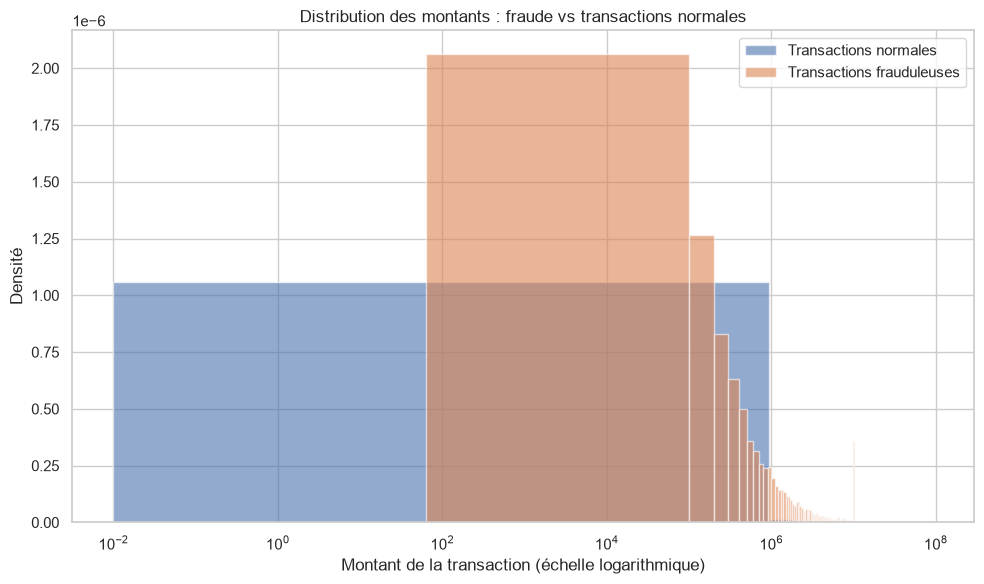

In [37]:
plt.figure(figsize=(10, 6))

plt.hist(
    normales[normales > 0],
    bins=100,
    alpha=0.6,
    density=True,
    label="Transactions normales"
)

plt.hist(
    fraudes[fraudes > 0],
    bins=100,
    alpha=0.6,
    density=True,
    label="Transactions frauduleuses"
)

plt.xscale("log")
plt.xlabel("Montant de la transaction (échelle logarithmique)")
plt.ylabel("Densité")
plt.title("Distribution des montants : fraude vs transactions normales")
plt.legend()
plt.tight_layout()
plt.show()

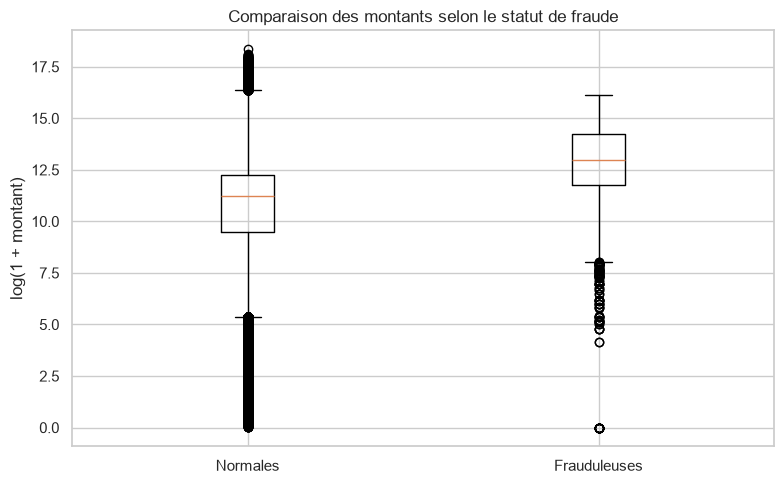

In [38]:
plt.figure(figsize=(8, 5))

plt.boxplot(
    [
        np.log1p(normales),
        np.log1p(fraudes)
    ],
    tick_labels=["Normales", "Frauduleuses"]
)

plt.ylabel("log(1 + montant)")
plt.title("Comparaison des montants selon le statut de fraude")
plt.tight_layout()
plt.show()

In [39]:
# Créer 10 tranches contenant approximativement le même nombre
# de transactions, selon les quantiles du montant
df_analyse = df.copy()

df_analyse["tranche_montant"] = pd.qcut(
    df_analyse["amount"],
    q=10,
    duplicates="drop"
)

analyse_montants = (
    df_analyse.groupby("tranche_montant", observed=True)
    .agg(
        nombre_transactions=("isFraud", "size"),
        nombre_fraudes=("isFraud", "sum"),
        taux_fraude=("isFraud", "mean")
    )
)

analyse_montants["taux_fraude_pct"] = (
    analyse_montants["taux_fraude"] * 100
).round(4)

print(analyse_montants)

                           nombre_transactions  nombre_fraudes  taux_fraude  \
tranche_montant                                                               
(-0.001, 4501.3]                        636263             148     0.000233   
(4501.3, 9866.158]                      636261             128     0.000201   
(9866.158, 18092.028]                   636262             148     0.000233   
(18092.028, 36371.35]                   636262             365     0.000574   
(36371.35, 74871.94]                    636262             617     0.000970   
(74871.94, 122563.784]                  636262             592     0.000930   
(122563.784, 176801.919]                636262             581     0.000913   
(176801.919, 246611.22]                 636262             503     0.000791   
(246611.22, 365423.309]                 636262             719     0.001130   
(365423.309, 92445516.64]               636262            4412     0.006934   

                           taux_fraude_pct  
tranch

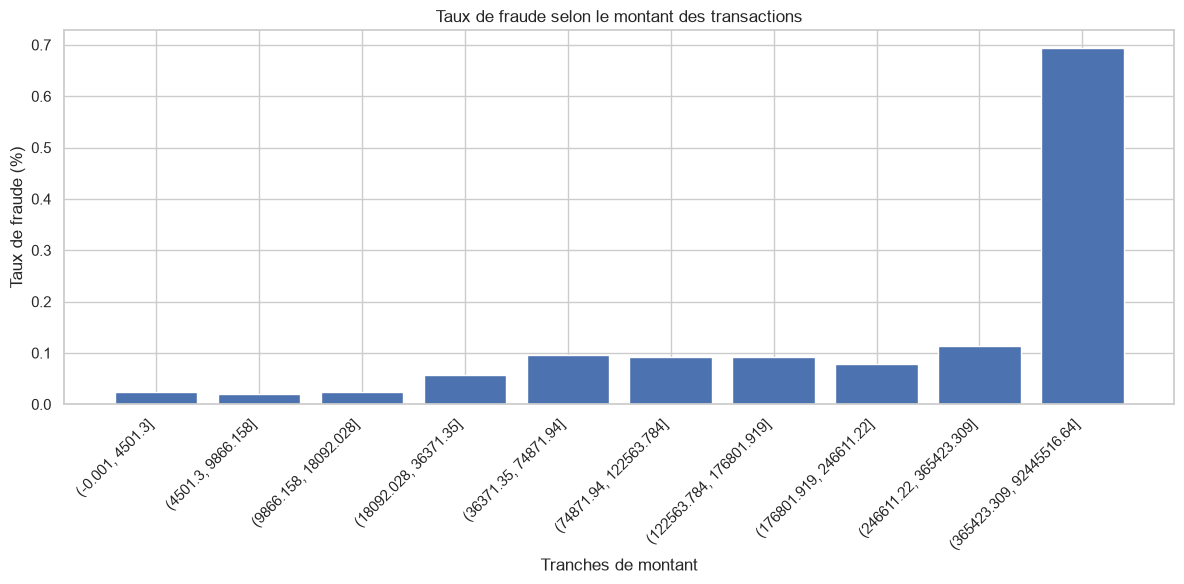

In [40]:
plt.figure(figsize=(12, 6))

plt.bar(
    analyse_montants.index.astype(str),
    analyse_montants["taux_fraude_pct"]
)

plt.xlabel("Tranches de montant")
plt.ylabel("Taux de fraude (%)")
plt.title("Taux de fraude selon le montant des transactions")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

**`
### Remarques issues de la première exploration des données (EDA)

À la suite de l'analyse exploratoire, plusieurs observations intéressantes ont été relevées :

1. **Montant nul (`amount = 0`) :** toutes les transactions observées avec un montant nul sont frauduleuses dans le jeu de données étudié. Cette caractéristique pourrait constituer un indicateur intéressant pour la détection des fraudes.

2. **Identifiants des comptes :** toutes les transactions frauduleuses observées concernent des comptes dont les identifiants commencent par `C`, aussi bien pour l'émetteur (`nameOrig`) que pour le destinataire (`nameDest`).

3. **Montant élevé :** le taux de fraude semble augmenter dans les tranches de montants les plus élevés. Le montant pourrait donc apporter une information utile au modèle de détection.

4. **Types de transactions frauduleuses :** les fraudes observées concernent uniquement les opérations `CASH_OUT` et `TRANSFER`. Aucun cas de fraude n'a été observé pour les autres types de transactions.

5. **Fréquence des fraudes par compte :**
   - **Émetteurs (`nameOrig`) :** chaque compte émetteur frauduleux apparaît une seule fois parmi les transactions frauduleuses observées.
   - **Destinataires (`nameDest`) :** plusieurs fréquences d'apparition ont été observées, notamment 1, 2, 3 à 5, 6 à 10 et plus de 10 transactions frauduleuses par compte.

### Conclusion préliminaire

Ces observations suggèrent que le montant, le type de transaction et certaines caractéristiques des comptes pourraient être utiles pour la détection des fraudes. Elles devront toutefois être vérifiées et approfondies avant la modélisation.

**Précaution méthodologique :** ces résultats décrivent le jeu de données analysé et ne constituent pas nécessairement des règles générales de fraude. En particulier, les identifiants bruts des comptes ne doivent pas être considérés automatiquement comme des variables prédictives fiables, et toute caractéristique construite à partir de l'historique des fraudes devra éviter les fuites de données (*data leakage*).
`**

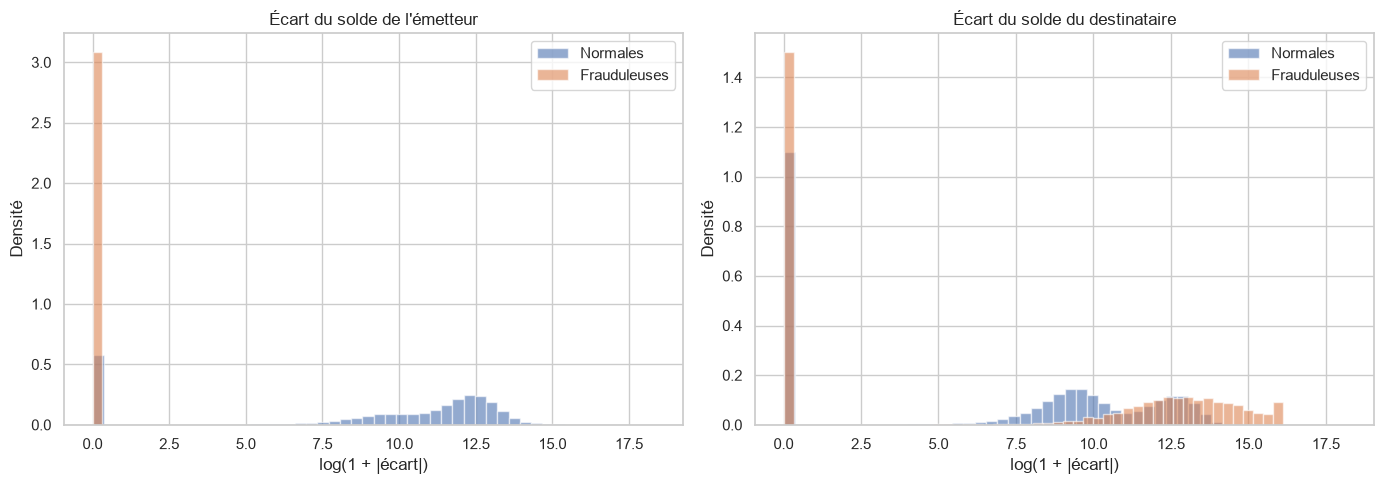

In [55]:


fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, col, titre in [
    (axes[0], "ecartOrig", "Écart du solde de l'émetteur"),
    (axes[1], "ecartDest", "Écart du solde du destinataire")
]:
    for fraude, label in [(0, "Normales"), (1, "Frauduleuses")]:
        valeurs = df.loc[df["isFraud"] == fraude, col].dropna()
        ax.hist(
            np.log1p(np.abs(valeurs)),
            bins=50,
            alpha=0.6,
            density=True,
            label=label
        )

    ax.set_title(titre)
    ax.set_xlabel("log(1 + |écart|)")
    ax.set_ylabel("Densité")
    ax.legend()

plt.tight_layout()
plt.show()

nous avons appliqué le logarithme pour rendre la distribution des écarts plus lisible, pas parce que les données doivent obligatoirement être transformées.

In [56]:
df.head(5)

,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud,ecartOrig,ecartDest
0,1,PAYMENT,9839.64,C1231006815,170136.0,160296.36,M1979787155,0.0,0.0,0,0,1.455192e-11,-9839.64
1,1,PAYMENT,1864.28,C1666544295,21249.0,19384.72,M2044282225,0.0,0.0,0,0,-1.136868e-12,-1864.28
2,1,TRANSFER,181.00,C1305486145,181.0,0.00,C553264065,0.0,0.0,1,0,0.000000e+00,-181.00
3,1,CASH_OUT,181.00,C840083671,181.0,0.00,C38997010,21182.0,0.0,1,0,0.000000e+00,-21363.00
4,1,PAYMENT,11668.14,C2048537720,41554.0,29885.86,M1230701703,0.0,0.0,0,0,0.000000e+00,-11668.14


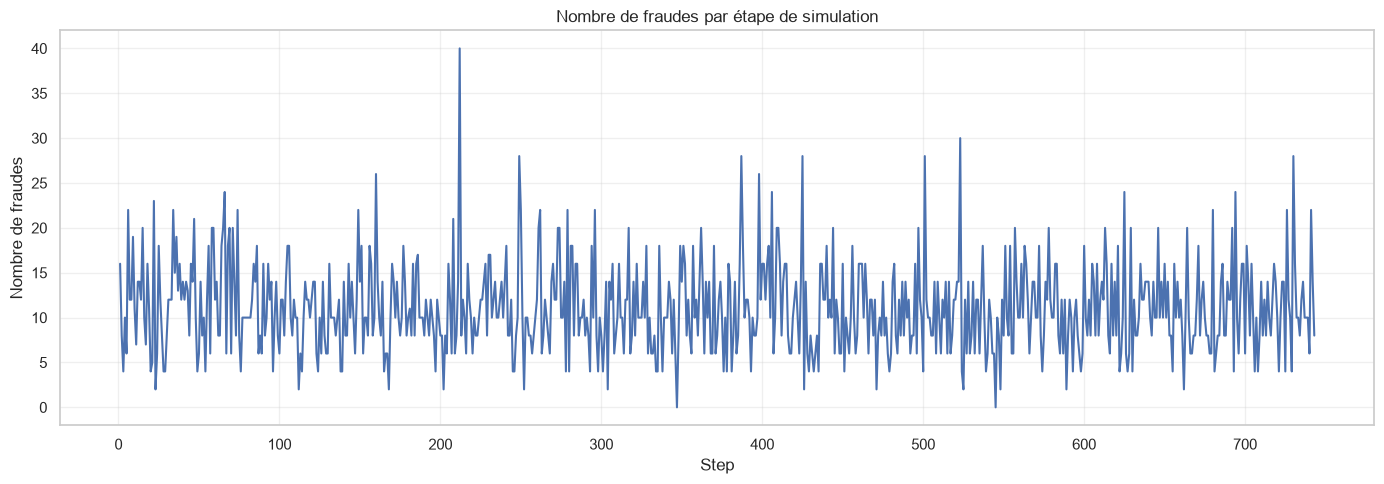

In [57]:

fraudes_par_step = (
    df.groupby("step")["isFraud"]
    .agg(
        nombre_transactions="count",
        nombre_fraudes="sum",
        taux_fraude="mean"
    )
)

fraudes_par_step["taux_fraude_pct"] = (
    fraudes_par_step["taux_fraude"] * 100
)

plt.figure(figsize=(14, 5))
plt.plot(
    fraudes_par_step.index,
    fraudes_par_step["nombre_fraudes"]
)

plt.xlabel("Step")
plt.ylabel("Nombre de fraudes")
plt.title("Nombre de fraudes par étape de simulation")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

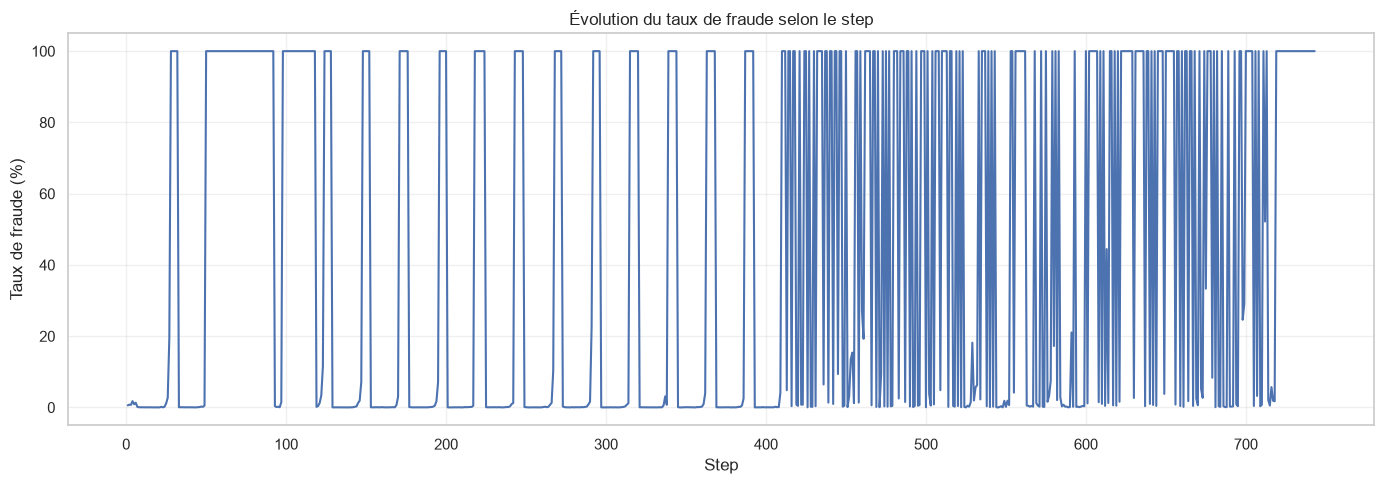

In [58]:
plt.figure(figsize=(14, 5))

plt.plot(
    fraudes_par_step.index,
    fraudes_par_step["taux_fraude_pct"]
)

plt.xlabel("Step")
plt.ylabel("Taux de fraude (%)")
plt.title("Évolution du taux de fraude selon le step")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

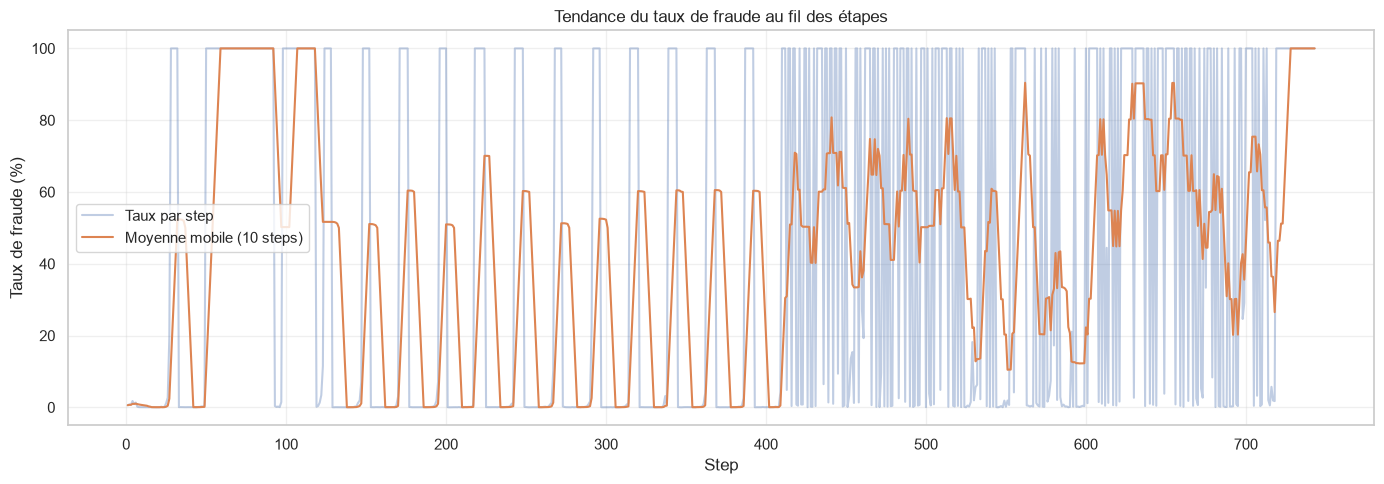

In [52]:
fraudes_par_step["taux_mobile_10"] = (
    fraudes_par_step["taux_fraude_pct"]
    .rolling(window=10, min_periods=1)
    .mean()
)

plt.figure(figsize=(14, 5))

plt.plot(
    fraudes_par_step.index,
    fraudes_par_step["taux_fraude_pct"],
    alpha=0.35,
    label="Taux par step"
)

plt.plot(
    fraudes_par_step.index,
    fraudes_par_step["taux_mobile_10"],
    label="Moyenne mobile (10 steps)"
)

plt.xlabel("Step")
plt.ylabel("Taux de fraude (%)")
plt.title("Tendance du taux de fraude au fil des étapes")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [53]:
etapes_suspectes = (
    fraudes_par_step[
        fraudes_par_step["nombre_fraudes"] > 0
    ]
    .sort_values("taux_fraude_pct", ascending=False)
)

print(etapes_suspectes[
    ["nombre_transactions", "nombre_fraudes", "taux_fraude_pct"]
].head(15))

      nombre_transactions  nombre_fraudes  taux_fraude_pct
step                                                      
728                    10              10            100.0
743                     8               8            100.0
729                     4               4            100.0
730                    28              28            100.0
731                    16              16            100.0
732                    10              10            100.0
727                    12              12            100.0
414                    16              16            100.0
415                    16              16            100.0
417                     6               6            100.0
418                     6               6            100.0
421                    14              14            100.0
424                    14              14            100.0
425                    28              28            100.0
427                    14              14            100

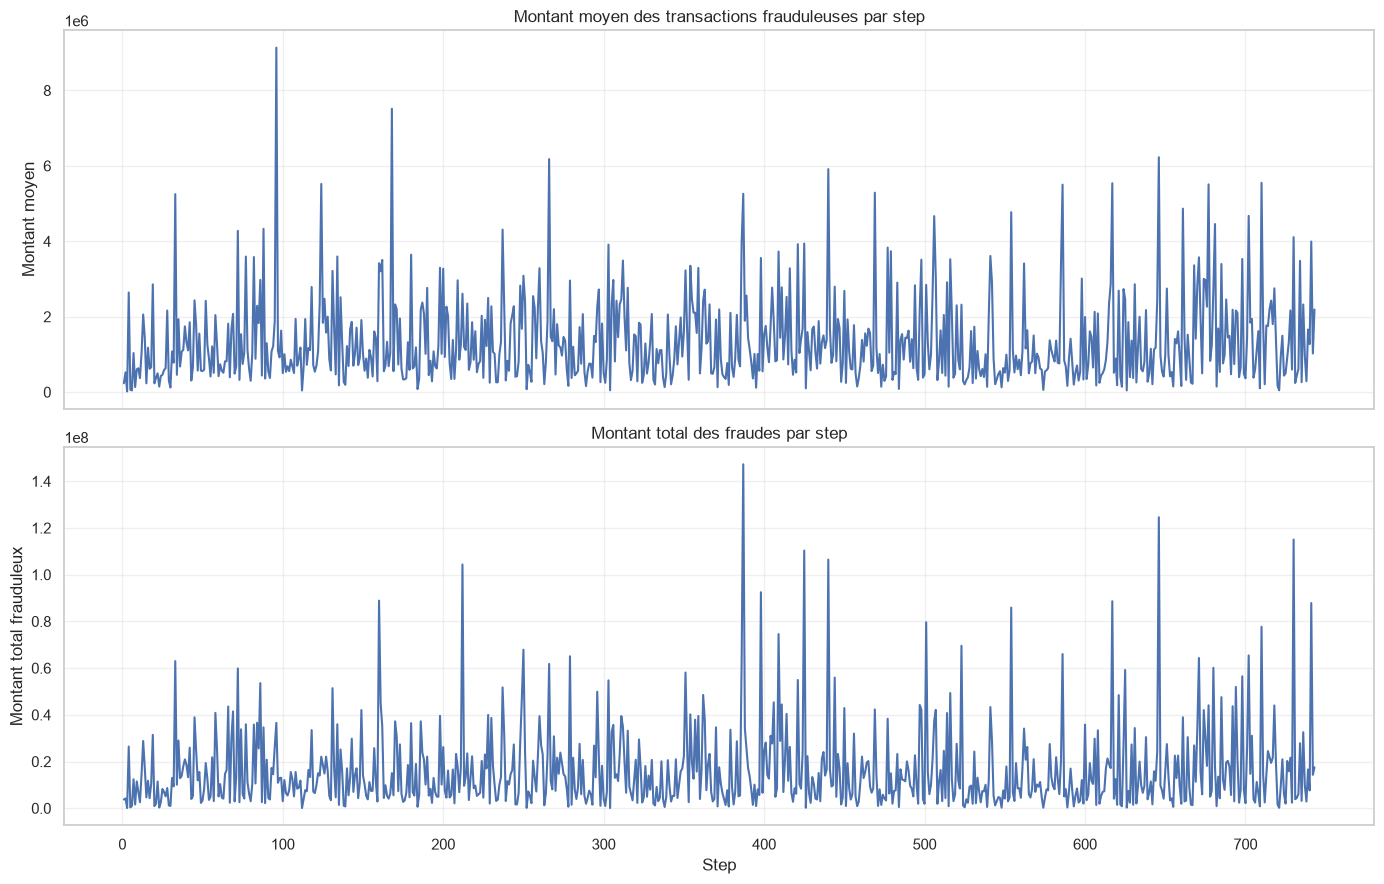

In [54]:
fraudes = df[df["isFraud"] == 1]

montants_fraudes_par_step = (
    fraudes.groupby("step")["amount"]
    .agg(
        nombre_fraudes="count",
        montant_moyen="mean",
        montant_median="median",
        montant_total="sum"
    )
)

fig, axes = plt.subplots(2, 1, figsize=(14, 9), sharex=True)

axes[0].plot(
    montants_fraudes_par_step.index,
    montants_fraudes_par_step["montant_moyen"]
)
axes[0].set_ylabel("Montant moyen")
axes[0].set_title("Montant moyen des transactions frauduleuses par step")
axes[0].grid(alpha=0.3)

axes[1].plot(
    montants_fraudes_par_step.index,
    montants_fraudes_par_step["montant_total"]
)
axes[1].set_xlabel("Step")
axes[1].set_ylabel("Montant total frauduleux")
axes[1].set_title("Montant total des fraudes par step")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

**feature engeneering**

In [60]:
df["amount_nul"] = (
    df["amount"] == 0
).astype("int8")

In [62]:
df["ratioOrig"] = (
    df["amount"] /
    df["oldbalanceOrg"].replace(0, np.nan)
)

df["ratioOrig"] = df["ratioOrig"].replace(
    [np.inf, -np.inf], np.nan
)

df["ratioOrig_nul"] = (
    df["oldbalanceOrg"] == 0
).astype("int8")

In [63]:
df["ratioDest"] = (
    df["amount"] /
    df["newbalanceDest"].replace(0, np.nan)
)

df["ratioDest"] = df["ratioDest"].replace(
    [np.inf, -np.inf], np.nan
)

df["ratioDest_nul"] = (
    df["newbalanceDest"] == 0
).astype("int8")

In [64]:
nouvelles_features = [
    "ratioOrig",
    "ratioOrig_nul",
    "ratioDest",
    "ratioDest_nul",
    "amount_nul"
]

print(df[nouvelles_features].describe().T)
print("\nValeurs manquantes :")
print(df[nouvelles_features].isna().sum())

                   count        mean          std           min       25%  \
ratioOrig      4260171.0  122.040104  4149.277081  1.765481e-08  0.074596   
ratioOrig_nul  6362620.0    0.330438     0.470371  0.000000e+00  0.000000   
ratioDest      3923187.0    4.017283  5524.639806  0.000000e+00  0.069811   
ratioDest_nul  6362620.0    0.383401     0.486215  0.000000e+00  0.000000   
amount_nul     6362620.0    0.000003     0.001586  0.000000e+00  0.000000   

                    50%       75%         max  
ratioOrig      0.740758  6.655752   3925475.6  
ratioOrig_nul  0.000000  1.000000         1.0  
ratioDest      0.218011  0.512823  10937629.0  
ratioDest_nul  0.000000  1.000000         1.0  
amount_nul     0.000000  0.000000         1.0  

Valeurs manquantes :
ratioOrig        2102449
ratioOrig_nul          0
ratioDest        2439433
ratioDest_nul          0
amount_nul             0
dtype: int64


In [66]:
for col in nouvelles_features:
    print(f"\n--- {col} ---")
    print(
        df.groupby("isFraud")[col]
        .agg(["mean", "median", "count"])
        .round(4)
    )


--- ratioOrig ---
             mean  median    count
isFraud                           
0        122.2727  0.7347  4251999
1          0.9988  1.0000     8172

--- ratioOrig_nul ---
           mean  median    count
isFraud                         
0        0.3309     0.0  6354407
1        0.0050     0.0     8213

--- ratioDest ---
           mean  median    count
isFraud                         
0        4.0208  0.2178  3919065
1        0.7037  0.8143     4122

--- ratioDest_nul ---
           mean  median    count
isFraud                         
0        0.3833     0.0  6354407
1        0.4981     0.0     8213

--- amount_nul ---
           mean  median    count
isFraud                         
0        0.0000     0.0  6354407
1        0.0019     0.0     8213


In [70]:
from pathlib import Path

output_dir = Path("../data/processed")
output_dir.mkdir(parents=True, exist_ok=True)

df.to_parquet(
    output_dir / "fraud_eda_features.parquet",
    index=False
)

print("Sauvegarde terminée.")

Sauvegarde terminée.
